# Feature Engineering

---

1. Import packages
2. Load data
3. Feature engineering

---

## 1. Import packages

In [1]:
import pandas as pd

---
## 2. Load data

In [2]:
df = pd.read_csv('./clean_data_after_eda.csv')
df["date_activ"] = pd.to_datetime(df["date_activ"], format='%Y-%m-%d')
df["date_end"] = pd.to_datetime(df["date_end"], format='%Y-%m-%d')
df["date_modif_prod"] = pd.to_datetime(df["date_modif_prod"], format='%Y-%m-%d')
df["date_renewal"] = pd.to_datetime(df["date_renewal"], format='%Y-%m-%d')

In [3]:
df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,var_6m_price_off_peak_var,var_6m_price_peak_var,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,0.000131,4.100838e-05,0.000908,2.086294,99.530517,44.235794,2.086425,9.953056e+01,44.236702,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,0.000003,1.217891e-03,0.000000,0.009482,0.000000,0.000000,0.009485,1.217891e-03,0.000000,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,0.000004,9.450150e-08,0.000000,0.000000,0.000000,0.000000,0.000004,9.450150e-08,0.000000,0


---

## 3. Feature engineering

### Difference between off-peak prices in December and preceding January

Below is the code created by your colleague to calculate the feature described above. Use this code to re-create this feature and then think about ways to build on this feature to create features with a higher predictive power.

In [4]:
price_df = pd.read_csv('price_data.csv')
price_df["price_date"] = pd.to_datetime(price_df["price_date"], format='%Y-%m-%d')
price_df.head()

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


In [6]:
# Group off-peak prices by companies and month
monthly_price_by_id = price_df.groupby(['id', 'price_date']).agg({'price_off_peak_var': 'mean', 'price_off_peak_fix': 'mean'}).reset_index()

# Get january and december prices
jan_prices = monthly_price_by_id.groupby('id').first().reset_index()
dec_prices = monthly_price_by_id.groupby('id').last().reset_index()

# Calculate the difference
diff = pd.merge(dec_prices.rename(columns={'price_off_peak_var': 'dec_1', 'price_off_peak_fix': 'dec_2'}), jan_prices.drop(columns='price_date'), on='id')
diff['offpeak_diff_dec_january_energy'] = diff['dec_1'] - diff['price_off_peak_var']
diff['offpeak_diff_dec_january_power'] = diff['dec_2'] - diff['price_off_peak_fix']
diff = diff[['id', 'offpeak_diff_dec_january_energy','offpeak_diff_dec_january_power']]
diff.head()

,id,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power
0,0002203ffbb812588b632b9e628cc38d,-0.006192,0.162916
1,0004351ebdd665e6ee664792efc4fd13,-0.004104,0.177779
2,0010bcc39e42b3c2131ed2ce55246e3c,0.050443,1.500000
3,0010ee3855fdea87602a5b7aba8e42de,-0.010018,0.162916
4,00114d74e963e47177db89bc70108537,-0.003994,-0.000001


Now it is time to get creative and to conduct some of your own feature engineering! Have fun with it, explore different ideas and try to create as many as you can!

---
## 3.1 Merge Estelle's Baseline Off-Peak Price Difference & Expand to Peak / Mid-Peak
First, we merge the December vs. January off-peak energy and power price differences (`offpeak_diff_dec_january_energy`, `offpeak_diff_dec_january_power`) into `df` on the shared `id` column. Next, we extend this logic to **Peak** and **Mid-Peak** tariffs, as well as computing **average cross-period price spreads** and **maximum monthly price swings** across 2015.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Merge Estelle's baseline off-peak difference features into df
df = pd.merge(df, diff, on='id')

# 1. Expand Dec vs. Jan price differences to Peak and Mid-Peak periods
monthly_all_prices = price_df.groupby(['id', 'price_date']).agg({
    'price_peak_var': 'mean',
    'price_mid_peak_var': 'mean',
    'price_peak_fix': 'mean',
    'price_mid_peak_fix': 'mean'
}).reset_index()

jan_all = monthly_all_prices.groupby('id').first().reset_index()
dec_all = monthly_all_prices.groupby('id').last().reset_index()

diff_all = pd.merge(
    dec_all.rename(columns={
        'price_peak_var': 'dec_peak_var',
        'price_mid_peak_var': 'dec_mid_var',
        'price_peak_fix': 'dec_peak_fix',
        'price_mid_peak_fix': 'dec_mid_fix'
    }),
    jan_all.drop(columns='price_date'),
    on='id'
)
diff_all['peak_diff_dec_january_energy'] = diff_all['dec_peak_var'] - diff_all['price_peak_var']
diff_all['midpeak_diff_dec_january_energy'] = diff_all['dec_mid_var'] - diff_all['price_mid_peak_var']
diff_all['peak_diff_dec_january_power'] = diff_all['dec_peak_fix'] - diff_all['price_peak_fix']
diff_all['midpeak_diff_dec_january_power'] = diff_all['dec_mid_fix'] - diff_all['price_mid_peak_fix']

diff_all = diff_all[[
    'id', 'peak_diff_dec_january_energy', 'midpeak_diff_dec_january_energy',
    'peak_diff_dec_january_power', 'midpeak_diff_dec_january_power'
]]
df = pd.merge(df, diff_all, on='id')

# 2. Average prices by client and cross-period price spreads (Off-Peak vs Peak vs Mid-Peak)
mean_prices = price_df.groupby('id').agg({
    'price_off_peak_var': 'mean',
    'price_peak_var': 'mean',
    'price_mid_peak_var': 'mean',
    'price_off_peak_fix': 'mean',
    'price_peak_fix': 'mean',
    'price_mid_peak_fix': 'mean'
}).reset_index()

mean_prices['off_peak_peak_var_mean_diff'] = mean_prices['price_off_peak_var'] - mean_prices['price_peak_var']
mean_prices['peak_mid_peak_var_mean_diff'] = mean_prices['price_peak_var'] - mean_prices['price_mid_peak_var']
mean_prices['off_peak_mid_peak_var_mean_diff'] = mean_prices['price_off_peak_var'] - mean_prices['price_mid_peak_var']
mean_prices['off_peak_peak_fix_mean_diff'] = mean_prices['price_off_peak_fix'] - mean_prices['price_peak_fix']
mean_prices['peak_mid_peak_fix_mean_diff'] = mean_prices['price_peak_fix'] - mean_prices['price_mid_peak_fix']
mean_prices['off_peak_mid_peak_fix_mean_diff'] = mean_prices['price_off_peak_fix'] - mean_prices['price_mid_peak_fix']
df = pd.merge(df, mean_prices, on='id')

# 3. Maximum monthly price variation (Max - Min across 2015) for each client
price_range = price_df.groupby('id').agg({
    'price_off_peak_var': lambda x: x.max() - x.min(),
    'price_peak_var': lambda x: x.max() - x.min(),
    'price_mid_peak_var': lambda x: x.max() - x.min(),
    'price_off_peak_fix': lambda x: x.max() - x.min(),
    'price_peak_fix': lambda x: x.max() - x.min(),
    'price_mid_peak_fix': lambda x: x.max() - x.min()
}).reset_index().rename(columns={
    'price_off_peak_var': 'max_diff_off_peak_var',
    'price_peak_var': 'max_diff_peak_var',
    'price_mid_peak_var': 'max_diff_mid_peak_var',
    'price_off_peak_fix': 'max_diff_off_peak_fix',
    'price_peak_fix': 'max_diff_peak_fix',
    'price_mid_peak_fix': 'max_diff_mid_peak_fix'
})
df = pd.merge(df, price_range, on='id')
print('Shape after price feature engineering:', df.shape)

Shape after price feature engineering: (14606, 68)


---
## 3.2 Expanding Date Columns & Behavioral Consumption Ratios
Raw date timestamps (`date_activ`, `date_end`, `date_modif_prod`, `date_renewal`) cannot be fed directly into a Random Forest classifier. Relative to the reference date (`2016-01-01`), we calculate:
- `months_activ`: Total months the client contract has been active.
- `months_to_end`: Remaining months until contract expiration.
- `months_modif_prod`: Months elapsed since the last product modification.
- `months_renewal`: Months elapsed since the last contract renewal.
- Calendar month indicators (`month_activ`, `month_end`, `month_modif_prod`, `month_renewal`).
- Behavioral usage ratios (`cons_last_month_ratio`, `forecast_cons_ratio`, `total_energy_cons_12m`, `elec_share_of_total_cons`).

In [8]:
# Reference date (January 1, 2016)
ref_date = pd.to_datetime('2016-01-01')

df['months_activ'] = ((ref_date - df['date_activ']).dt.days / 30.4375).round().astype(int)
df['months_to_end'] = ((df['date_end'] - ref_date).dt.days / 30.4375).round().astype(int)
df['months_modif_prod'] = ((ref_date - df['date_modif_prod']).dt.days / 30.4375).round().astype(int)
df['months_renewal'] = ((ref_date - df['date_renewal']).dt.days / 30.4375).round().astype(int)

# Extract calendar month components
df['month_activ'] = df['date_activ'].dt.month
df['month_end'] = df['date_end'].dt.month
df['month_modif_prod'] = df['date_modif_prod'].dt.month
df['month_renewal'] = df['date_renewal'].dt.month

# Behavioral consumption ratio & combined energy features
df['cons_last_month_ratio'] = df['cons_last_month'] / (df['cons_12m'] + 1)
df['forecast_cons_ratio'] = df['forecast_cons_12m'] / (df['cons_12m'] + 1)
df['total_energy_cons_12m'] = df['cons_12m'] + df['cons_gas_12m']
df['elec_share_of_total_cons'] = df['cons_12m'] / (df['total_energy_cons_12m'] + 1)

print(df[['months_activ', 'months_to_end', 'months_modif_prod', 'months_renewal', 'cons_last_month_ratio']].head())

   months_activ  months_to_end  months_modif_prod  months_renewal  cons_last_month_ratio
0            31              5                  2               6                    0.0
1            76              8                 76               4                    0.0
2            69              3                 69               8                    0.0
3            69              3                 69               8                    0.0
4            72              2                 72               9                    0.0


---
## 3.3 Log-Transforming Skewed Variables, Encoding Categories & Removing Redundant Columns
- **Log10 Transformation:** In Task 2 EDA, consumption and margin variables exhibited extreme positive skewness ($+6.0$ to $+36.6$). We apply $\log_{10}(x + 1)$ to stabilize their distributions.
- **Categorical Encoding:** We map `has_gas` (`'t' -> 1`, `'f' -> 0`) and one-hot encode `channel_sales` and `origin_up`.
- **Column Removal (Answering Step 1):**
  1. Raw datetime columns (`date_activ`, `date_end`, `date_modif_prod`, `date_renewal`) are removed after extracting tenure and month features.
  2. `margin_net_pow_ele` is removed because it is 99.99% identical to `margin_gross_pow_ele` ($r = 0.999914$, differing in only 2 of 14,606 rows).
  3. Combined variance columns (`var_year_price_off_peak`, `var_year_price_peak`, `var_year_price_mid_peak`, and their `6m` counterparts) are removed because they have a $1.000000$ correlation with the corresponding `*_fix` variance columns.

In [9]:
# Log10 transformation for heavily skewed numerical variables
skewed_cols = [
    'cons_12m', 'cons_gas_12m', 'cons_last_month', 'forecast_cons_12m',
    'forecast_cons_year', 'forecast_discount_energy', 'forecast_meter_rent_12m',
    'imp_cons', 'net_margin', 'pow_max', 'total_energy_cons_12m'
]
for col in skewed_cols:
    df[col] = np.log10(df[col].clip(lower=0) + 1)

# Encode binary and categorical features
df['has_gas'] = df['has_gas'].replace({'t': 1, 'f': 0}).astype(int)
df = pd.get_dummies(df, columns=['channel_sales', 'origin_up'], prefix=['channel', 'origin'], dtype=int)

# Remove raw dates and collinear/redundant features
cols_to_drop = [
    'date_activ', 'date_end', 'date_modif_prod', 'date_renewal',
    'margin_net_pow_ele',
    'var_year_price_off_peak', 'var_year_price_peak', 'var_year_price_mid_peak',
    'var_6m_price_off_peak', 'var_6m_price_peak', 'var_6m_price_mid_peak'
]
df = df.drop(columns=cols_to_drop)

print('Final cleaned & engineered dataset shape:', df.shape)

Final cleaned & engineered dataset shape: (14606, 81)


---
## 3.4 Visualizing Engineered Feature Distributions & Correlations with Churn

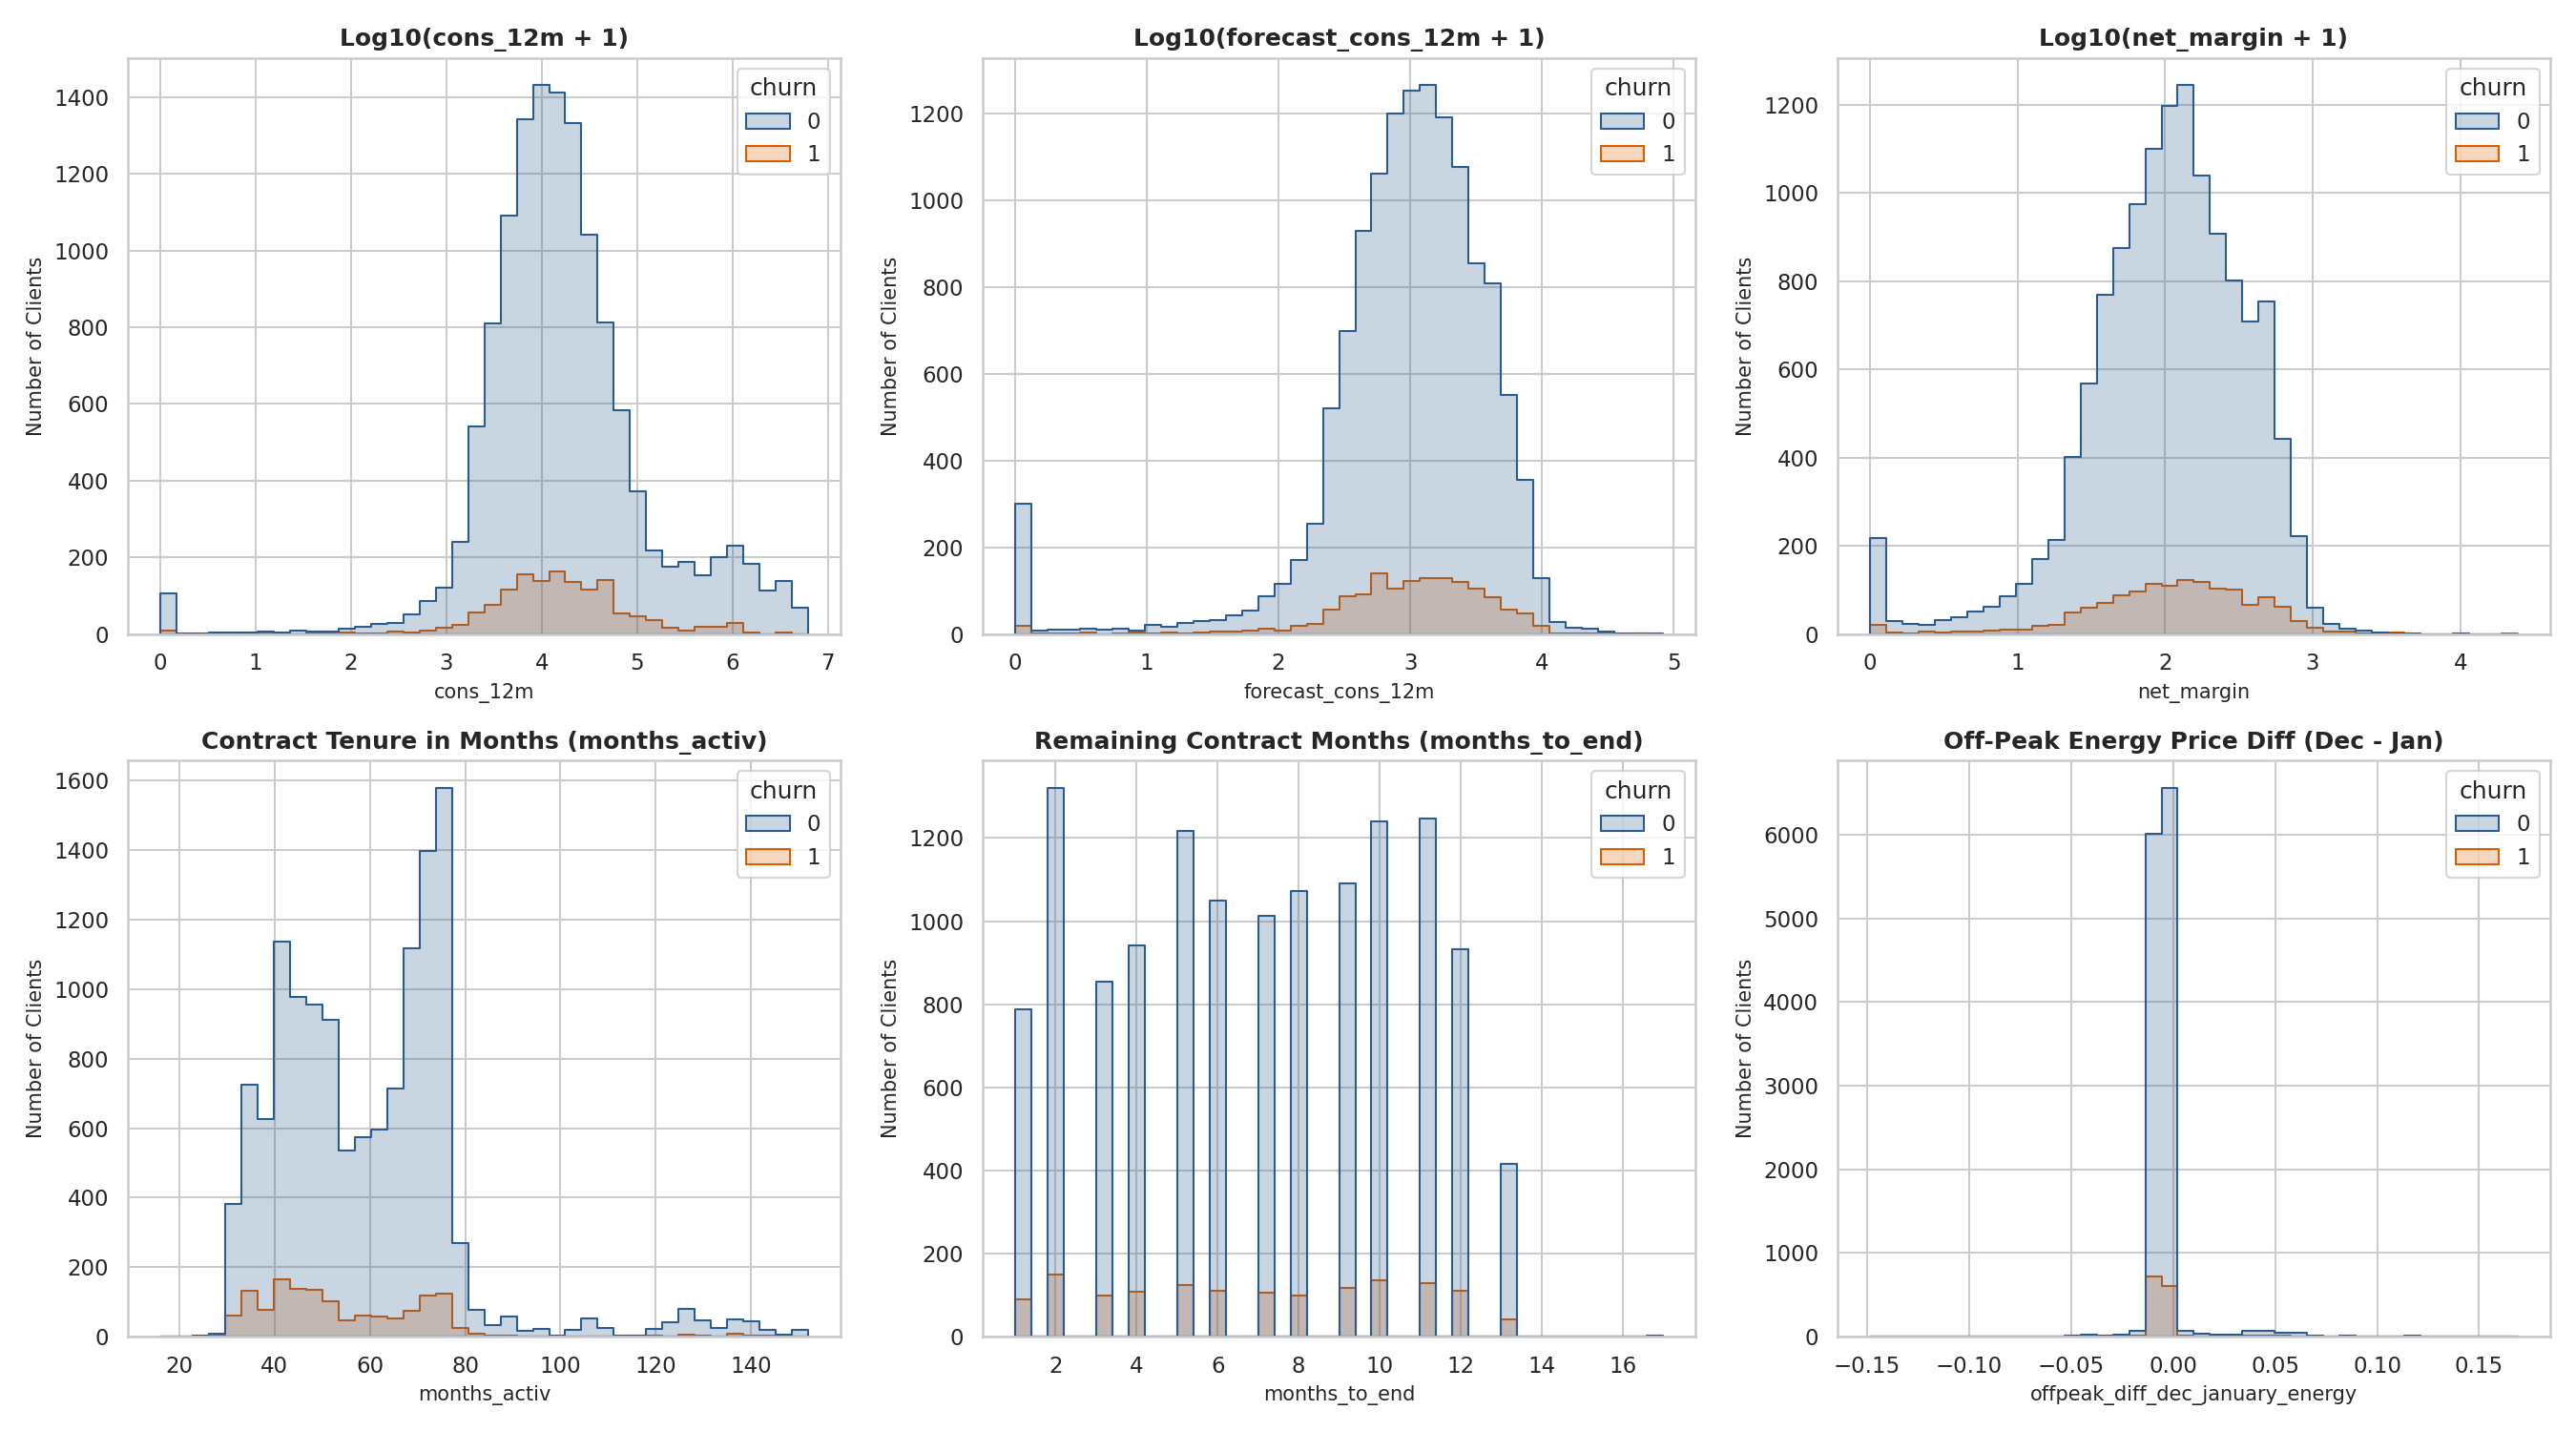

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
plot_cols = [
    ('cons_12m', 'Log10(cons_12m + 1)'),
    ('forecast_cons_12m', 'Log10(forecast_cons_12m + 1)'),
    ('net_margin', 'Log10(net_margin + 1)'),
    ('months_activ', 'Contract Tenure in Months (months_activ)'),
    ('months_to_end', 'Remaining Contract Months (months_to_end)'),
    ('offpeak_diff_dec_january_energy', 'Off-Peak Energy Price Diff (Dec - Jan)')
]
for idx, (col, title) in enumerate(plot_cols):
    r, c = divmod(idx, 3)
    sns.histplot(data=df, x=col, hue='churn', bins=40, ax=axs[r, c], palette={0: '#2b5c8f', 1: '#d95f02'}, element='step')
    axs[r, c].set_title(title, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

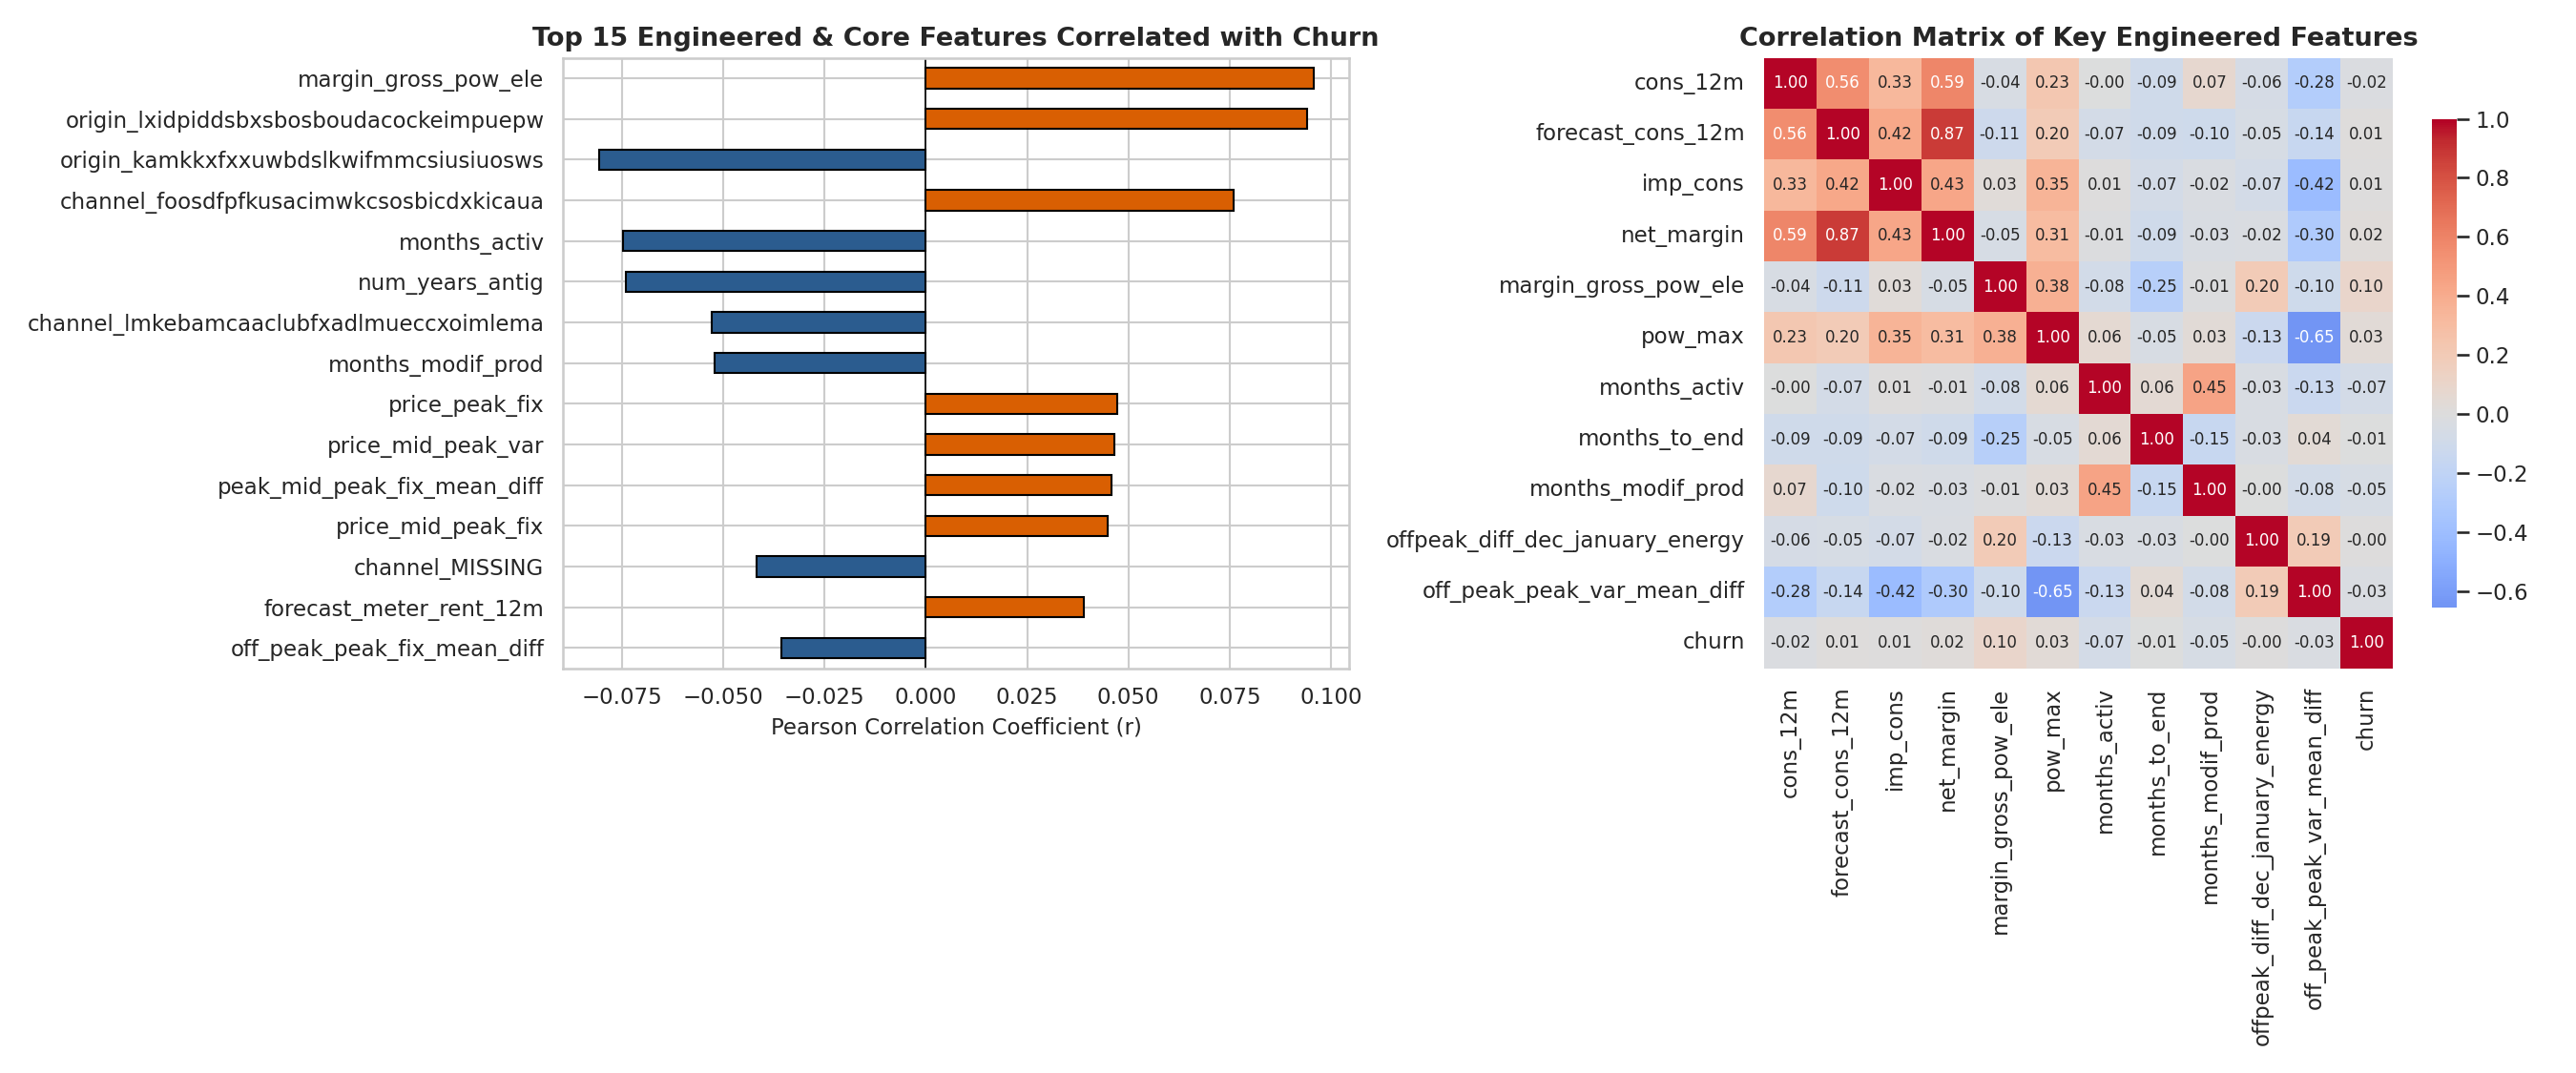

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(18, 7.5))
corrs = df.drop(columns=['id', 'churn']).apply(lambda x: x.corr(df['churn'])).sort_values(key=abs, ascending=True).tail(15)
colors = ['#d95f02' if v > 0 else '#2b5c8f' for v in corrs.values]
corrs.plot(kind='barh', ax=axs[0], color=colors, edgecolor='black')
axs[0].set_title('Top 15 Engineered & Core Features Correlated with Churn', fontsize=13, fontweight='bold')
axs[0].set_xlabel('Pearson Correlation Coefficient (r)')

heatmap_cols = [
    'cons_12m', 'forecast_cons_12m', 'imp_cons', 'net_margin', 'margin_gross_pow_ele',
    'pow_max', 'months_activ', 'months_to_end', 'months_modif_prod',
    'offpeak_diff_dec_january_energy', 'off_peak_peak_var_mean_diff', 'churn'
]
sns.heatmap(df[heatmap_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axs[1])
axs[1].set_title('Correlation Matrix of Key Engineered Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()